# A multivariate linear regression model for Rwandan food-product unit prices

This notebook builds a model that predicts the unit price in Rwandan francs (RWF) a household pays for
one food product line, and turns that model into a district comparison of what a small basket costs.

**Data:** `electricsheepafrica/africa-rwanda-eicv5-vup-farming-c5f851c8` (Rwanda EICV5 survey extract).

Read the sections in order. Every helper lives in the one Helpers cell below and is called from
everywhere else.

## Helpers

All reusable functions are defined here once. Later sections only call them.

In [1]:
import time
from functools import lru_cache
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from datasets import load_dataset
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

DATASET_ID = "electricsheepafrica/africa-rwanda-eicv5-vup-farming-c5f851c8"
TARGET = "s8cq15"  # unit price in RWF
RANDOM_STATE = 42
TEST_SIZE = 0.20
PRICE_MARGIN = 0.05
MODEL_PATH = Path.cwd().parent / "API" / "best_model.pkl"

REPEAT_VISIT_COLUMNS = [f"s8cq{i}" for i in range(5, 14)]

# The 16 columns the extract offers as candidates, before the reduction in Section C.
CANDIDATE_NUMERIC = REPEAT_VISIT_COLUMNS + ["s0q18m", "s0q18y"]
CANDIDATE_CATEGORICAL = ["s8cq0", "district", "ur", "s8cq14", "coicop_group"]
CANDIDATE_COLUMNS = CANDIDATE_CATEGORICAL + CANDIDATE_NUMERIC

# The five inputs a person can answer when asking for a price.
NUMERIC_FEATURES = ["s0q18m"]
CATEGORICAL_FEATURES = ["s8cq0", "s8cq14", "district", "ur"]
FEATURE_COLUMNS = ["s8cq0", "s8cq14", "district", "ur", "s0q18m"]

MODEL_INPUT_DROPS = {
    **{
        column: "repeat visit record: a user cannot supply a repeat visit"
        for column in REPEAT_VISIT_COLUMNS
    },
    "s0q18y": "survey year: every priced row is 2016 or 2017, so it cannot move the estimate",
    "province": "province of the district: it adds nothing once the district is known",
    "coicop_group": "COICOP division: it repeats the product family already held by s8cq0",
}

IDENTIFIER_COLUMNS = [
    "source_record_id", "country_iso3", "country_name", "id", "hhid",
    "license_id", "retrieved_at",
]
FRAME_DROPS = [
    "s8cq0d",  # Kinyarwanda label of s8cq0
    "s8cq1",   # full COICOP code, kept only through coicop_group
    "s8cq2",   # 87% missing, and its codes do not match the interview month
    "s8cq3",   # visit-record field a user cannot answer
    "s8cq4",   # second amount recorded in the same visit
    "clust",   # cluster id: 151 levels no user can supply
    "weight",  # survey design weight, not a price input
]


@lru_cache(maxsize=1)
def _raw_frame() -> pd.DataFrame:
    """The untouched extract, loaded once per session."""
    return load_dataset(DATASET_ID, split="train").to_pandas()


def load_clean():
    """Load the extract and apply every cleaning decision from Section B.

    Returns the cleaned frame and the household group id as separate objects:
    key_17 identifies a household, so it groups the split and never becomes a feature.
    """
    df = _raw_frame().copy()

    df["coicop_group"] = df["s8cq1"].astype("string").str.slice(0, 2)
    source_columns = [c for c in df.columns if c.startswith("source_")]
    df = df.drop(columns=IDENTIFIER_COLUMNS + source_columns + FRAME_DROPS)

    # "Not Applicable" and blanks become missing, so only real prices survive.
    df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

    # The visit shares are text; "Nothing" means zero of that item on that visit.
    for column in REPEAT_VISIT_COLUMNS:
        df[column] = pd.to_numeric(df[column].replace("Nothing", 0), errors="coerce")

    # A missing unit keeps its own category: the enumerator recorded no unit.
    df["s8cq14"] = df["s8cq14"].astype("object").fillna("unknown").astype(str)

    # Only rows that report a price can train or score a price model.
    df = df.loc[df[TARGET].notna()].reset_index(drop=True)
    household = df.pop("key_17")
    return df, household


def select_model_inputs(df):
    """Reduce the candidate frame to the five inputs plus the target."""
    return df[FEATURE_COLUMNS + [TARGET]].copy()


def build_preprocessor() -> ColumnTransformer:
    """Median imputation + scaling for the month, most-frequent + one-hot for categories."""
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, NUMERIC_FEATURES),
        ("categorical", categorical_pipe, CATEGORICAL_FEATURES),
    ])


def build_pipeline(estimator) -> Pipeline:
    """One pipeline per model: the preprocessor is fitted inside it, on training rows only."""
    return Pipeline([("prep", build_preprocessor()), ("model", estimator)])


def evaluate(model, X_train, X_test, y_train, y_test) -> dict:
    """Train and test error on the shared split; RMSE is reported on the test rows."""
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    return {
        "train_mse": train_mse,
        "test_mse": test_mse,
        "test_rmse": float(np.sqrt(test_mse)),
    }


def transform_splits(X_train, X_test):
    """Fit the shared preprocessor on training rows only, then transform both sides."""
    preprocessor = build_preprocessor()
    return preprocessor.fit_transform(X_train), preprocessor.transform(X_test)


def plot_scatter(ax, x, y, line=None):
    """Scatter x against y on ax, with an optional fitted line."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    ax.scatter(x, y, s=10, alpha=0.30, edgecolors="none", color="steelblue")
    if line is not None:
        grid = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
        names = getattr(line, "feature_names_in_", None)
        inputs = pd.DataFrame(grid, columns=list(names)) if names is not None else grid
        ax.plot(grid.ravel(), line.predict(inputs), color="crimson", linewidth=2)
    ax.grid(alpha=0.3)
    return ax


def predict_one(path, row) -> float:
    """Load a saved bundle and predict the price for one complete input row."""
    bundle = joblib.load(path)
    inputs = list(bundle["metadata"]["input_columns"])
    missing = [column for column in inputs if column not in row]
    if missing:
        raise KeyError(f"missing model inputs: {missing}")
    frame = pd.DataFrame([{column: row[column] for column in inputs}], columns=inputs)
    return float(bundle["pipeline"].predict(frame)[0])


def price_basket() -> pd.DataFrame:
    """The five most frequently priced food products, each with its usual unit."""
    cache = _raw_frame()
    price = pd.to_numeric(cache[TARGET], errors="coerce")
    priced = cache.loc[price.notna(), ["s8cq0", "s8cq1", "s8cq14"]]
    food = priced.loc[priced["s8cq1"].astype("string").str.slice(0, 2) == "01"]
    top = food["s8cq0"].value_counts().head(5).index.tolist()
    units = (
        food.loc[food["s8cq0"].isin(top)]
        .dropna(subset=["s8cq14"])
        .groupby("s8cq0")["s8cq14"]
        .agg(lambda values: values.mode().iloc[0])
    )
    return pd.DataFrame({"s8cq0": top, "s8cq14": units.reindex(top).to_numpy()})


def district_affordability(pipeline, metadata) -> pd.DataFrame:
    """Basket price per district in both settings, at the median interview month.

    Every district is scored with the same five products, the same unit per product
    and the same month, so the only thing that changes is where the household lives.
    """
    basket = price_basket()
    month = metadata["month_range"]["median"]
    rows = []
    for district in metadata["allowed_values"]["district"]:
        for setting in metadata["allowed_values"]["ur"]:
            frame = pd.DataFrame({
                "s8cq0": basket["s8cq0"],
                "s8cq14": basket["s8cq14"],
                "district": district,
                "ur": setting,
                "s0q18m": month,
            })
            rows.append({
                "district": district,
                "setting": setting,
                "basket_price_rwf": float(pipeline.predict(frame).sum()),
            })

    table = pd.DataFrame(rows).pivot(
        index="district", columns="setting", values="basket_price_rwf"
    )
    table.columns = [f"{column.lower()}_basket_rwf" for column in table.columns]
    table["mean_basket_rwf"] = table.mean(axis=1)
    return table.sort_values("mean_basket_rwf", ascending=False).round(0).astype(int)


def _source_feature(encoded_name: str) -> str:
    """Map an encoded column such as 'categorical__s8cq0_Dry beans' back to 's8cq0'."""
    body = encoded_name.split("__", 1)[-1]
    for column in sorted(FEATURE_COLUMNS, key=len, reverse=True):
        if body == column or body.startswith(column + "_"):
            return column
    return body


print("helpers ready")

helpers ready


## Section A: Mission and use case

This model estimates the **unit price in RWF** a household pays for a food product in a Rwandan
district. It answers one question a person can actually ask: what does a kilogram of this product cost
here, in this season?

**Who uses it**

* **Households budgeting** a week's shopping: they enter the product, the unit, their district and the
  setting, and get the likely cost of that line.
* **Farmers and traders benchmarking** a sale or a purchase: they compare the estimate with the price
  they are offered before agreeing to it.
* **NGOs and local planners comparing districts**: Section H prices the same five-product basket in
  every district, so one budget can be compared across markets instead of across anecdotes.

**What it is not.** Every estimate reflects the 2016 to 2017 EICV5 survey patterns only. These are not
live prices, they do not track today's market, and they must not be quoted as a current price list.

## Section B: Cleaning

The target is `s8cq15`, the unit price in RWF that a household reports for one product line. The
decisions below are applied inside `load_clean()`. Each one is inspected first, then justified.

In [2]:
df, household = load_clean()
print(f"rows: {len(df):,} | candidate columns: {len(CANDIDATE_COLUMNS)} | households: {household.nunique():,}")
df.head()

Using the latest cached version of the dataset since electricsheepafrica/africa-rwanda-eicv5-vup-farming-c5f851c8 couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /home/elijahladdie/.cache/huggingface/datasets/electricsheepafrica___africa-rwanda-eicv5-vup-farming-c5f851c8/default/0.0.0/845333fe1518b6c0adf0b23ae5b07c34dffe3ec4 (last modified on Thu Nov 19 17:21:15 2026).


rows: 19,947 | candidate columns: 16 | households: 1,058


,province,district,ur,s8cq0,s8cq5,s8cq6,s8cq7,s8cq8,s8cq9,s8cq10,s8cq11,s8cq12,s8cq13,s8cq14,s8cq15,s0q18m,s0q18y,coicop_group
0,Kigali City,Nyarugenge,Rural,Banana fruit _Imineke_,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,unknown,400.0,4,2017,01
1,Kigali City,Nyarugenge,Rural,Banana - cooking _Inyamunyo_,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,unknown,300.0,4,2017,01
2,Kigali City,Nyarugenge,Rural,Amarante _small leafed green_,1.0,0.0,0.5,0.0,0.5,1.0,0.0,0.0,0.0,unknown,100.0,4,2017,01
3,Kigali City,Nyarugenge,Rural,Local banana juice,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,unknown,300.0,4,2017,01
4,Kigali City,Nyarugenge,Rural,Fresh bean,0.0,0.0,0.0,0.0,3.0,0.0,2.0,0.0,0.0,unknown,400.0,4,2017,01


### B1 evidence: the visit-record fields and the unit column

`s8cq3` and `s8cq4` are filled in by the enumerator during the visit. `s8cq5` to `s8cq13` hold a share
for each repeated visit to the same product line. The tables below show how often each one is filled,
so the drops rest on what the columns are rather than on a guess.

In [3]:
raw = _raw_frame()
price = pd.to_numeric(raw[TARGET], errors="coerce")
priced = price.notna()

evidence = pd.DataFrame({
    "non_zero_rows": [
        int((pd.to_numeric(raw[c], errors="coerce").fillna(0) != 0).sum())
        for c in ["s8cq3", "s8cq4"]
    ],
    "non_zero_when_price_present": [
        int((pd.to_numeric(raw.loc[priced, c], errors="coerce").fillna(0) != 0).sum())
        for c in ["s8cq3", "s8cq4"]
    ],
    "non_zero_when_price_absent": [
        int((pd.to_numeric(raw.loc[~priced, c], errors="coerce").fillna(0) != 0).sum())
        for c in ["s8cq3", "s8cq4"]
    ],
    "rows_with_price": [int(priced.sum())] * 2,
}, index=["s8cq3", "s8cq4"])
display(evidence)

shares = raw[REPEAT_VISIT_COLUMNS].replace("Nothing", 0).apply(pd.to_numeric, errors="coerce")
visits_per_row = shares.gt(0).sum(axis=1)
visit_table = visits_per_row.value_counts().sort_index().to_frame("rows")
visit_table.index.name = "visit_share_columns_filled_in_one_row"
print("how many of s8cq5-s8cq13 are filled on the same row:")
print(visit_table.to_string())

labels_per_product = raw.groupby("s8cq0")["s8cq0d"].nunique()
print(f"\nKinyarwanda labels per product: max={labels_per_product.max()}, "
      f"products with more than one label={int((labels_per_product > 1).sum())} "
      f"of {labels_per_product.size}")

,non_zero_rows,non_zero_when_price_present,non_zero_when_price_absent,rows_with_price
s8cq3,6224,5719,505,19947
s8cq4,4154,3886,268,19947


how many of s8cq5-s8cq13 are filled on the same row:
                                         rows
visit_share_columns_filled_in_one_row        
0                                      157743
1                                        2789
2                                        1534
3                                        1047
4                                         729
5                                         662
6                                        1239
7                                          78
8                                          56
9                                         167

Kinyarwanda labels per product: max=2, products with more than one label=2 of 101


### B2 justification: what I dropped and why

**`s8cq3` and `s8cq4` are dropped because a user would not know them when asking for a price.** Both are
recorded by the enumerator during the interview; they describe what happened on that visit, not a
property of the product or of the market. Someone asking for a price has no way to supply either value,
so a model that reads them cannot serve a real request.

**`s8cq5` to `s8cq13` are dropped as repeat-visit records.** The second table above shows one row
carrying several of these shares at once: they are per-visit records of the same product line, not
inputs a person can answer. They stay in the frame for the exploration in Section C, which is the
evidence for the eight-feature rule, and `select_model_inputs()` removes them before any model is fitted.

**`s8cq0d` is dropped as a duplicate.** It is the Kinyarwanda label of `s8cq0`; 99 of 101 products map
to exactly one label, so it repeats the product in a second language.

**`s8cq1` is dropped after engineering `coicop_group`.** Its first two digits give the COICOP division,
and the full code repeats the product already held by `s8cq0`.

**`clust` and `weight` are dropped as survey-design fields.** `clust` is a cluster id with 151 levels
and `weight` is the sampling weight. Neither is something a person asking for a price can supply.

**Three candidate columns never become model inputs**, one line each: `s0q18y` is the survey year and
every priced row is 2016 or 2017, so it cannot move the estimate; `province` repeats the district; and
`coicop_group` repeats the product family already held by `s8cq0`. Section C prints the full reduction
table.

In [4]:
print(df["s8cq14"].value_counts())
unknown_share = float((df["s8cq14"] == "unknown").mean())
print(f"\nshare of priced rows with no unit recorded: {unknown_share:.2%}")

s8cq14
unknown    13041
Kg          6361
Igice        317
Lit          223
Ipaki          5
Name: count, dtype: int64

share of priced rows with no unit recorded: 65.38%


### B3: what the unit column actually contains

The counts above list every unit value present in the priced rows: `Kg`, `Lit`, `Igice` (a piece or
portion) and `Ipaki` (a packet), plus `unknown` for the rows where no unit was recorded. 65.38% of the
priced rows have no unit, so `unknown` is kept as its own category: it is the largest single value in the
column, and dropping it would remove those rows entirely.

In [5]:
missing = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
decision = {
    "s8cq14": "keep: the unit separates kg, litres, pieces and packets",
    "s8cq2": "drop: above the 60% rule",
    "s8cq15": "target: above the 60% rule, so it is never an input",
}
missing["decision"] = [decision.get(c, "keep") for c in missing.index]
display(missing)

print(f"rows kept after dropping rows without a recorded price: {len(df):,}")
print(f"price range after cleaning: {df[TARGET].min():.0f} to {df[TARGET].max():.0f} RWF, "
      f"median {df[TARGET].median():.0f}")

,missing,missing_pct,decision
s8cq14,150494,90.64,"keep: the unit separates kg, litres, pieces an..."
s8cq2,144852,87.24,drop: above the 60% rule
s8cq15,137139,82.59,"target: above the 60% rule, so it is never an ..."


rows kept after dropping rows without a recorded price: 19,947
price range after cleaning: 1 to 5000 RWF, median 250


### B4: the 60% missing rule

Three columns sit above 60% missing, and each one is handled differently.

**`s8cq2` is dropped.** It is 87.24% missing, and its 12 codes do not match the interview month
`s0q18m` (agreement 7.3%), so it cannot be interpreted reliably either.

**`s8cq15` is not usable as an input.** It is 82.59% missing, and it is the target: imputing a target
would invent the prices we want to learn. It stays the target, and only the 19,947 rows that report a
price are kept.

**`s8cq14` also breaks the rule and is kept anyway.** In the full extract it is 90.64% missing, and
among the priced rows 65.38% of units are `unknown`. Dropping the column would erase the only signal that
separates kilograms from litres, and imputing a unit would invent one, so `unknown` becomes its own
category.

In [6]:
checks = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
})
display(checks)

assert len(df) >= 1000, "too few rows"
assert len(CANDIDATE_COLUMNS) >= 8, "the candidate set no longer evidences the 8-feature rule"
assert df[CANDIDATE_NUMERIC].apply(pd.api.types.is_numeric_dtype).all(), "numeric dtype missing"
assert df[CANDIDATE_CATEGORICAL].apply(pd.api.types.is_string_dtype).all(), "categorical dtype missing"
assert "key_17" not in df.columns, "the household id must never stay in the feature frame"

print(f"rows: {len(df):,} (needs >= 1,000)")
print(f"columns: {df.shape[1]} | candidate features: {len(CANDIDATE_COLUMNS)} "
      f"({len(CANDIDATE_NUMERIC)} numeric, {len(CANDIDATE_CATEGORICAL)} categorical; needs >= 8)")
print("checks passed")

,dtype,unique_values
province,str,5
district,str,27
ur,str,2
s8cq0,str,99
s8cq5,float64,1300
s8cq6,float64,1267
s8cq7,float64,1275
s8cq8,float64,1207
s8cq9,float64,1230
s8cq10,float64,1191


rows: 19,947 (needs >= 1,000)
columns: 18 | candidate features: 16 (11 numeric, 5 categorical; needs >= 8)
checks passed


## Section C: Exploration

In [7]:
candidates = pd.DataFrame({
    "dtype": df[CANDIDATE_COLUMNS].dtypes.astype(str),
    "role": ["categorical" if c in CANDIDATE_CATEGORICAL else "numeric" for c in CANDIDATE_COLUMNS],
    "unique_values": df[CANDIDATE_COLUMNS].nunique(),
}, index=CANDIDATE_COLUMNS)
display(candidates)

print(f"candidate columns: {len(CANDIDATE_COLUMNS)} over {len(df):,} rows "
      f"(the rule needs at least 8 features and 1,000 rows)")
assert len(CANDIDATE_COLUMNS) >= 8 and len(df) >= 1000

,dtype,role,unique_values
s8cq0,str,categorical,99
district,str,categorical,27
ur,str,categorical,2
s8cq14,str,categorical,5
coicop_group,string,categorical,3
s8cq5,float64,numeric,1300
s8cq6,float64,numeric,1267
s8cq7,float64,numeric,1275
s8cq8,float64,numeric,1207
s8cq9,float64,numeric,1230


candidate columns: 16 over 19,947 rows (the rule needs at least 8 features and 1,000 rows)


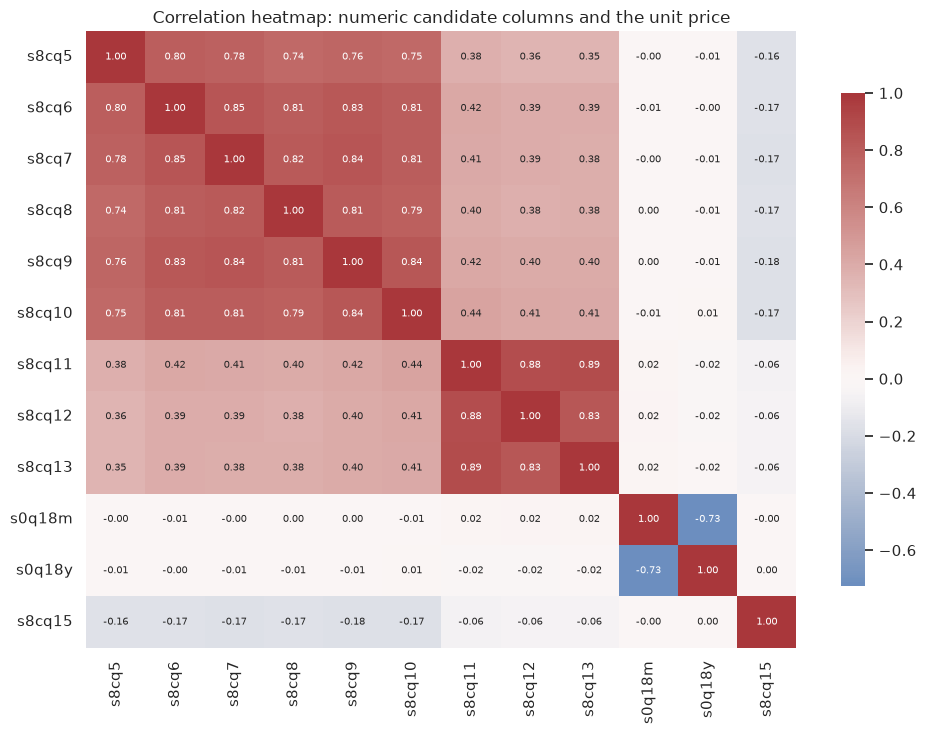

s8cq9    -0.1755
s8cq10   -0.1747
s8cq7    -0.1743
s8cq6    -0.1728
s8cq8    -0.1661
s8cq5    -0.1650
s8cq11   -0.0589
s8cq13   -0.0581
s8cq12   -0.0579
s0q18m   -0.0021
s0q18y    0.0008


In [8]:
corr = df[CANDIDATE_NUMERIC + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation heatmap: numeric candidate columns and the unit price")
plt.tight_layout()
plt.show()

corr_to_target = corr[TARGET].drop(TARGET).sort_values()
print(corr_to_target.round(4).to_string())

The heatmap covers the eleven numeric candidates plus the target. No single numeric column carries
the unit price: the strongest link is `s8cq9` at r = -0.18, and the other visit shares sit between
-0.06 and -0.17. The `s8cq5` to `s8cq13` block is internally correlated at 0.35 to 0.89, which is what
repeat-visit records look like: they overlap each other. The interview date columns `s0q18m` and
`s0q18y` are essentially zero.

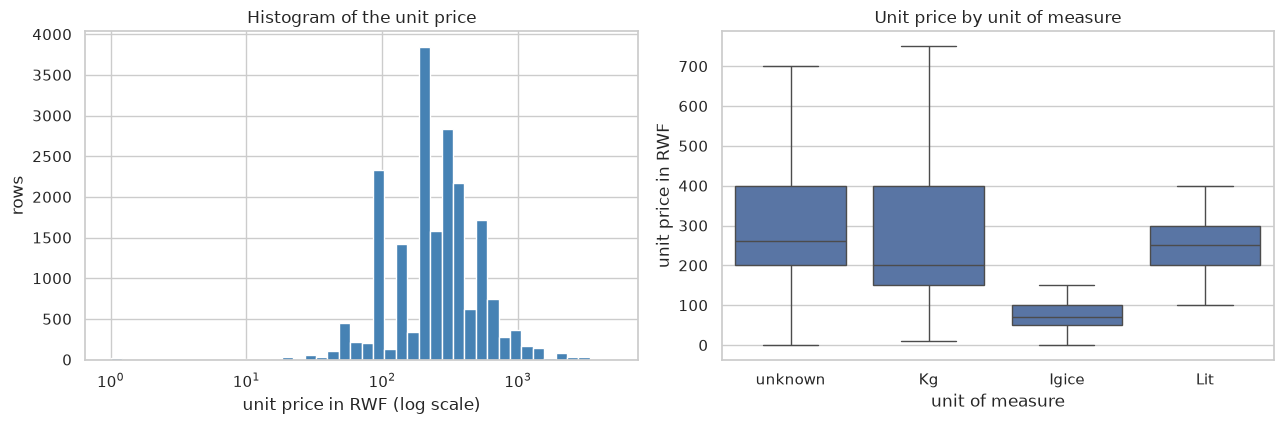

count    19947.00
mean       324.21
std        309.18
min          1.00
25%        160.00
50%        250.00
75%        400.00
max       5000.00


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

bins = np.logspace(np.log10(df[TARGET].min()), np.log10(df[TARGET].max()), 45)
axes[0].hist(df[TARGET], bins=bins, color="steelblue", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_xlabel("unit price in RWF (log scale)")
axes[0].set_ylabel("rows")
axes[0].set_title("Histogram of the unit price")

units = df["s8cq14"].value_counts().index[:4].tolist()
sns.boxplot(data=df[df["s8cq14"].isin(units)], x="s8cq14", y=TARGET,
            order=units, showfliers=False, ax=axes[1])
axes[1].set_xlabel("unit of measure")
axes[1].set_ylabel("unit price in RWF")
axes[1].set_title("Unit price by unit of measure")

plt.tight_layout()
plt.show()

print(df[TARGET].describe().round(2).to_string())

The target is strongly right-skewed: the median is 250 RWF, the mean 324 RWF and the tail reaches
5,000 RWF, so a handful of rows sit far above the mass. Decision: cap the target at its 99th percentile,
computed on the training rows only, so the tail cannot drag the fit. Section D does this, and the cap
lands at 1,500 RWF.

The box plot explains why the unit must stay in the model. Kg, Lit, Igice and Ipaki sit on different
scales and different spreads, so a price of 300 RWF means different things across units. Decision: keep
`s8cq14` as a categorical input instead of pooling prices as if they were comparable.

In [10]:
kept_reasons = {
    "s8cq0": "product: the item being priced",
    "s8cq14": "unit of measure: kg, litres, pieces and packets price differently",
    "district": "district: the local market the user names",
    "ur": "rural or urban setting: the same product prices differently",
    "s0q18m": "interview month: prices move with the season",
}
reduction = pd.DataFrame(
    {
        "kept_as_input": [column in FEATURE_COLUMNS for column in CANDIDATE_COLUMNS + ["province"]],
        "reason": [
            kept_reasons[column] if column in kept_reasons else MODEL_INPUT_DROPS[column]
            for column in CANDIDATE_COLUMNS + ["province"]
        ],
    },
    index=CANDIDATE_COLUMNS + ["province"],
)
display(reduction)

model_df = select_model_inputs(df)
print(f"candidate columns: {len(CANDIDATE_COLUMNS)} -> model inputs: {len(FEATURE_COLUMNS)}")
print(f"model rows: {len(model_df):,} | columns: {list(model_df.columns)}")
assert list(model_df.columns) == FEATURE_COLUMNS + [TARGET]

,kept_as_input,reason
s8cq0,True,product: the item being priced
district,True,district: the local market the user names
ur,True,rural or urban setting: the same product price...
s8cq14,True,"unit of measure: kg, litres, pieces and packet..."
coicop_group,False,COICOP division: it repeats the product family...
s8cq5,False,repeat visit record: a user cannot supply a re...
s8cq6,False,repeat visit record: a user cannot supply a re...
s8cq7,False,repeat visit record: a user cannot supply a re...
s8cq8,False,repeat visit record: a user cannot supply a re...
s8cq9,False,repeat visit record: a user cannot supply a re...


candidate columns: 16 -> model inputs: 5
model rows: 19,947 | columns: ['s8cq0', 's8cq14', 'district', 'ur', 's0q18m', 's8cq15']


Sixteen candidate columns are on the table, which is what evidences the eight-feature rule before the
reduction. The model keeps five of them: the ones a person can answer when asking for a price, namely
the product, the unit, the district, the setting and the month.

Everything else is dropped for the reason printed in the table. The visit shares and the two visit
fields record the interview rather than the market; `s0q18y` is the survey year and every priced row is
2016 or 2017, so it cannot move the estimate; `province` adds nothing once the district is known;
`coicop_group` repeats the product family already carried by `s8cq0`.

## Section D: Split and preprocess

A grouped 80/20 split on `key_17`, so one household never lands in both sides, a cap taken from the
training rows only, and one preprocessor fitted inside every pipeline.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

X = model_df[FEATURE_COLUMNS]
y = model_df[TARGET]

splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups=household))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]

overlap = set(household.loc[X_train.index]) & set(household.loc[X_test.index])
assert not overlap, "a household appears in both splits"

CAP = float(y_train.quantile(0.99))
y_train = y_train.clip(upper=CAP)
y_test = y_test.clip(upper=CAP)

print(f"households: {household.nunique():,} | train rows: {len(X_train):,} | test rows: {len(X_test):,}")
print(f"households in both splits: {len(overlap)}")
print(f"99th-percentile cap from the training rows: {CAP:.1f} RWF")
print(f"capped train max: {y_train.max():.1f} | capped test max: {y_test.max():.1f}")

households: 1,058 | train rows: 15,838 | test rows: 4,109
households in both splits: 0
99th-percentile cap from the training rows: 1500.0 RWF
capped train max: 1500.0 | capped test max: 1500.0


`GroupShuffleSplit` splits on `key_17`, the household group id that `load_clean()` returns separately.
No household appears in both sets: 1,058 households spread over 15,838 training rows and 4,109 test
rows. The same household usually reports several products, so a plain row split would let the model learn
a household's price level from its other rows and then score against that memory.

The cap of 1,500 RWF comes from the training target only. The test target is clipped with that same
value, so both sides share one scale and the tail cannot drag the fit. The preprocessor is not fitted
here: it lives inside each pipeline, so it only ever sees training rows.

## Section E: Four models

`SGDRegressor` is tuned first over learning rate, regularisation and epochs. Then all four models are
scored with `evaluate` on the same test rows, and the best linear model is compared with a log1p wrapper
fitted on the same pipeline.

In [12]:
from sklearn.linear_model import SGDRegressor

tuning_rows = []
for penalty in ["l2", "l1"]:
    for alpha in [1e-5, 1e-4, 1e-3, 1e-2]:
        for eta0 in [1e-4, 1e-3, 1e-2, 1e-1]:
            for epochs in [10, 40, 100, 200]:
                candidate = build_pipeline(SGDRegressor(
                    loss="squared_error", penalty=penalty, alpha=alpha, eta0=eta0,
                    learning_rate="constant", max_iter=epochs, tol=None,
                    random_state=RANDOM_STATE,
                ))
                candidate.fit(X_train, y_train)
                tuning_rows.append({
                    "penalty": penalty, "alpha": alpha, "eta0": eta0,
                    "learning_rate": "constant", "epochs": epochs,
                    **evaluate(candidate, X_train, X_test, y_train, y_test),
                })

# invscaling as one extra option per penalty, at the middle learning rate and the longest budget.
for penalty in ["l2", "l1"]:
    candidate = build_pipeline(SGDRegressor(
        loss="squared_error", penalty=penalty, alpha=1e-3, eta0=1e-3,
        learning_rate="invscaling", max_iter=200, tol=None, random_state=RANDOM_STATE,
    ))
    candidate.fit(X_train, y_train)
    tuning_rows.append({
        "penalty": penalty, "alpha": 1e-3, "eta0": 1e-3,
        "learning_rate": "invscaling", "epochs": 200,
        **evaluate(candidate, X_train, X_test, y_train, y_test),
    })

tuning = pd.DataFrame(tuning_rows).sort_values("test_mse").reset_index(drop=True)
best_config = tuning.iloc[0]
print(f"configurations tried: {len(tuning)}")
print("best configuration:",
      {k: best_config[k] for k in ["penalty", "alpha", "eta0", "learning_rate", "epochs"]})
print("\ninvscaling rows:")
print(tuning[tuning["learning_rate"] == "invscaling"]
      .round({"train_mse": 1, "test_mse": 1, "test_rmse": 1}).to_string(index=False))
display(tuning.head(10).round({"train_mse": 1, "test_mse": 1, "test_rmse": 1}))

configurations tried: 130
best configuration: {'penalty': 'l1', 'alpha': np.float64(1e-05), 'eta0': np.float64(0.001), 'learning_rate': 'constant', 'epochs': np.int64(200)}

invscaling rows:
penalty  alpha  eta0 learning_rate  epochs  train_mse  test_mse  test_rmse
     l1  0.001 0.001    invscaling     200    29649.2   31028.3      176.1
     l2  0.001 0.001    invscaling     200    30271.2   31513.8      177.5


,penalty,alpha,eta0,learning_rate,epochs,train_mse,test_mse,test_rmse
0,l1,0.00001,0.001,constant,200,16659.5,20228.9,142.2
1,l1,0.00010,0.001,constant,200,16659.7,20229.1,142.2
2,l1,0.00100,0.001,constant,200,16661.6,20230.2,142.2
3,l2,0.00001,0.001,constant,200,16667.8,20235.4,142.3
4,l1,0.01000,0.001,constant,200,16699.4,20301.2,142.5
5,l2,0.00010,0.001,constant,200,16775.1,20327.3,142.6
6,l1,0.00100,0.010,constant,100,16568.0,20360.5,142.7
7,l1,0.00010,0.010,constant,100,16575.0,20371.6,142.7
8,l2,0.00001,0.010,constant,100,16591.6,20392.8,142.8
9,l1,0.00001,0.010,constant,100,16582.8,20394.0,142.8


In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

estimators = {
    "SGDRegressor": SGDRegressor(
        loss="squared_error", penalty=best_config["penalty"], alpha=best_config["alpha"],
        eta0=best_config["eta0"], learning_rate=best_config["learning_rate"],
        max_iter=int(best_config["epochs"]), tol=None, random_state=RANDOM_STATE,
    ),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE
    ),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=120, max_depth=20, min_samples_leaf=2,
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

fitted = {}
rows = []
for name, estimator in estimators.items():
    pipeline = build_pipeline(estimator)
    started = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    fitted[name] = pipeline
    rows.append({"model": name, "fit_seconds": fit_seconds,
                 **evaluate(pipeline, X_train, X_test, y_train, y_test)})

results = (
    pd.DataFrame(rows).set_index("model")
    [["train_mse", "test_mse", "test_rmse", "fit_seconds"]]
    .sort_values("test_mse")
)
results.round({"train_mse": 1, "test_mse": 1, "test_rmse": 1, "fit_seconds": 2})

,train_mse,test_mse,test_rmse,fit_seconds
model,,,,
LinearRegression,16388.6,20075.4,141.7,0.26
SGDRegressor,16659.5,20228.9,142.2,0.53
RandomForestRegressor,18758.1,27540.9,166.0,1.79
DecisionTreeRegressor,39384.2,42264.5,205.6,0.12


**The model with the lowest test MSE is `LinearRegression`**, at 20,075.4 against a train MSE of
16,388.6, so the two are close and it is not overfitting. Its test RMSE is 141.7 RWF, which is the error
to quote when a user asks how far off an estimate can be.

`SGDRegressor` keeps `penalty="l1"`, `alpha=1e-05`, `eta0=0.001`, `learning_rate="constant"` and 200
epochs after the extended grid, and still lands 153 MSE behind the closed-form fit. The grid was extended
where the earlier best row sat on the edge: `eta0` below 0.001, `alpha` below 0.0001, up to 200 epochs,
plus one `invscaling` option per penalty. The new best row sits on the `alpha` floor of 1e-05 and on the
longest epoch budget, while `eta0=0.001` is now interior, and both `invscaling` rows are far worse
(31,028.3 and 31,513.8).

The tree is capped at depth 8 and the forest at depth 20 with 120 trees. Both underfit plainly, and the
train column shows it: the tree reaches only 39,384.2 and the forest 18,758.1, both worse than the linear
fit's 16,388.6 on the same rows, so neither can represent the price surface even where it has seen the
answers. Their test errors, 42,264.5 and 27,540.9, follow from that same limit. I keep the caps because
both train in seconds, and I report them as they are instead of lifting the limit to make the ensemble
look competitive.

In [14]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor

linear_names = ["LinearRegression", "SGDRegressor"]
best_linear_name = results.loc[linear_names, "test_mse"].idxmin()
best_linear_pipeline = fitted[best_linear_name]

log_name = f"{best_linear_name} on log1p(price)"
log_pipeline = TransformedTargetRegressor(
    regressor=clone(best_linear_pipeline),
    func=np.log1p,
    inverse_func=np.expm1,
)
log_pipeline.fit(X_train, y_train)

comparison = pd.DataFrame([
    {"model": best_linear_name,
     **evaluate(best_linear_pipeline, X_train, X_test, y_train, y_test)},
    {"model": log_name, **evaluate(log_pipeline, X_train, X_test, y_train, y_test)},
]).set_index("model")

candidates = {**fitted, log_name: log_pipeline}
scores = pd.concat([
    results[["train_mse", "test_mse", "test_rmse"]],
    comparison.loc[[log_name], ["train_mse", "test_mse", "test_rmse"]],
]).sort_values("test_mse")

best_name = scores["test_mse"].idxmin()
best_pipeline = candidates[best_name]

print(comparison.round(1).to_string())
print(f"\nkept: {best_name} | test MSE {scores.loc[best_name, 'test_mse']:.1f} "
      f"| test RMSE {scores.loc[best_name, 'test_rmse']:.1f} RWF")

                                  train_mse  test_mse  test_rmse
model                                                           
LinearRegression                    16388.6   20075.4      141.7
LinearRegression on log1p(price)    17889.4   21419.9      146.4

kept: LinearRegression | test MSE 20075.4 | test RMSE 141.7 RWF


The log1p wrapper reuses a clone of `LinearRegression`, so its preprocessor is fitted inside the wrapper
on the training rows only. It predicts `expm1` of the fitted log price, which puts its output back on the
original RWF scale, so the two test MSE values above are directly comparable.

Taking logs raises the test MSE from 20,075.4 to 21,419.9, so the plain `LinearRegression` is kept. The
wrapper pays off when a heavy tail dominates the loss; here the 99th-percentile cap has already removed
that tail, and the log fit gives up more than it gains.

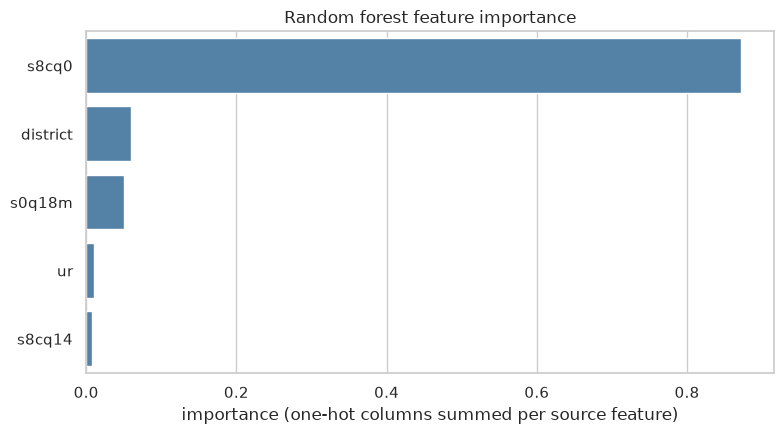

encoded columns: 132 | source features: 5


,importance,share_pct
s8cq0,0.8721,87.2
district,0.0596,6.0
s0q18m,0.0501,5.0
ur,0.0099,1.0
s8cq14,0.0083,0.8


In [15]:
rf_pipeline = fitted["RandomForestRegressor"]
encoded_names = rf_pipeline.named_steps["prep"].get_feature_names_out()
importances = pd.Series(
    rf_pipeline.named_steps["model"].feature_importances_, index=encoded_names
)
grouped = importances.groupby(_source_feature).sum().sort_values(ascending=False)

importance_df = grouped.head(10).to_frame("importance")
importance_df["share_pct"] = (importance_df["importance"] * 100).round(1)
importance_df["importance"] = importance_df["importance"].round(4)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=grouped.head(10).values, y=grouped.head(10).index, ax=ax, color="steelblue")
ax.set_xlabel("importance (one-hot columns summed per source feature)")
ax.set_ylabel("")
ax.set_title("Random forest feature importance")
plt.tight_layout()
plt.show()

print(f"encoded columns: {len(encoded_names)} | source features: {grouped.size}")
importance_df

**Feature importance note.** The capped forest concentrates almost everything on the product:
`s8cq0` carries 87.2% of the importance, `district` 6.0%, `s0q18m` 5.0%, `ur` 1.0% and `s8cq14` 0.8%.

That is a sensible reading. Which product is being priced, and where, moves the unit price far more than
when the question is asked or which unit is recorded, especially since most priced rows carry no unit. It
also explains the earlier heatmap: the raw numeric correlations are weak because the effect runs through
categories rather than through a straight line, which is why the categorical-aware linear model wins
Section E.

## Section F: Required plots

The loss curve comes from `partial_fit`, with train and test MSE after every epoch. The pair of scatters
uses the correlation feature chosen from the remaining numeric columns. The only numeric column left is
the interview month, whose correlation with the price is -0.00, so the plots use the product mean price
encoded as a number instead. That substitution is explained under the plots.

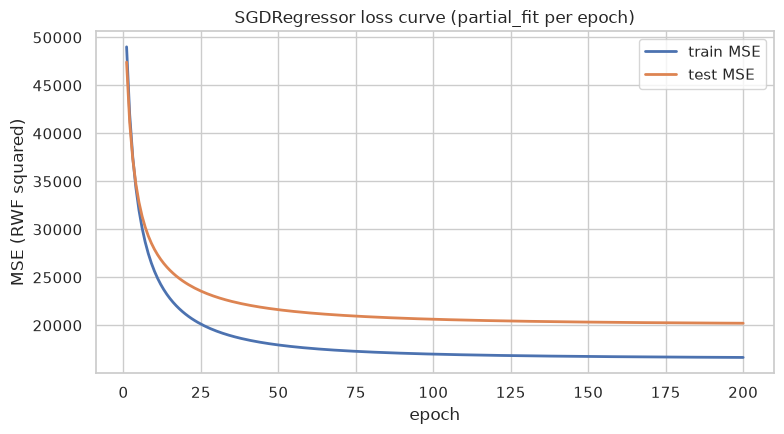

,epoch,train_mse,test_mse,test_rmse
0,1,49015.6,47431.9,217.8
100,101,16994.8,20627.0,143.6
199,200,16657.3,20222.1,142.2


In [16]:
X_train_matrix, X_test_matrix = transform_splits(X_train, X_test)

curve_model = SGDRegressor(
    loss="squared_error", penalty=best_config["penalty"], alpha=best_config["alpha"],
    eta0=best_config["eta0"], learning_rate=best_config["learning_rate"],
    random_state=RANDOM_STATE,
)

history = []
for epoch in range(1, int(best_config["epochs"]) + 1):
    curve_model.partial_fit(X_train_matrix, y_train)
    history.append({
        "epoch": epoch,
        **evaluate(curve_model, X_train_matrix, X_test_matrix, y_train, y_test),
    })

history = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history["epoch"], history["train_mse"], label="train MSE", linewidth=2)
ax.plot(history["epoch"], history["test_mse"], label="test MSE", linewidth=2)
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (RWF squared)")
ax.set_title("SGDRegressor loss curve (partial_fit per epoch)")
ax.legend()
plt.tight_layout()
plt.show()

history.iloc[[0, len(history) // 2, -1]].round(1)

The curve starts high and falls steeply: train MSE drops from 49,015.6 at epoch 1 to 16,994.8 by
epoch 101, and test MSE from 47,431.9 to 20,627.0. The last hundred epochs add little, taking train to
16,657.3 and test to 20,222.1, about 340 and 405 MSE respectively.

From the early epochs onward train sits below test, and by epoch 200 the two are roughly 3,560 apart,
which is the usual distance between a fit and unseen rows rather than a sign of memorising. The
200-epoch budget chosen in tuning is where the curve still gains a little without the two lines pulling
further apart.

correlation between product mean price and unit price: r = 0.843


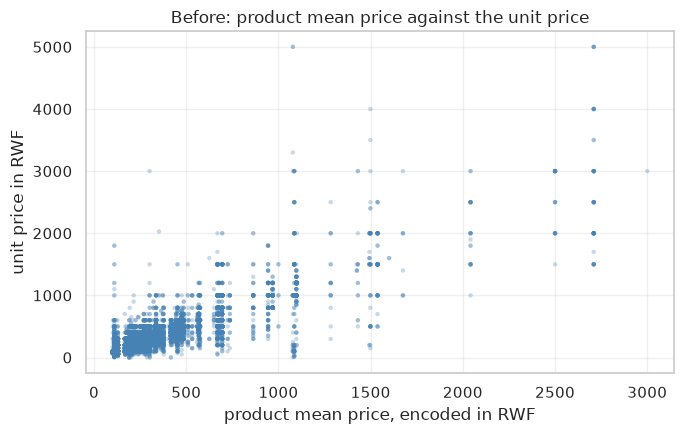

In [17]:
# Only the interview month is numeric after the reduction, so the picture encodes the product mean
# price as a number instead. That column is built from the target, which makes it leaky: it is used
# for this plot only and never becomes a model input.
product_mean_price = df.groupby("s8cq0")[TARGET].mean()
plot_x = df["s8cq0"].map(product_mean_price)
plot_y = df[TARGET]
correlation = float(np.corrcoef(plot_x, plot_y)[0, 1])
print(f"correlation between product mean price and unit price: r = {correlation:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_scatter(ax, plot_x, plot_y)
ax.set_xlabel("product mean price, encoded in RWF")
ax.set_ylabel("unit price in RWF")
ax.set_title("Before: product mean price against the unit price")
plt.tight_layout()
plt.show()

Only the interview month is numeric after the reduction, so this pair of plots encodes the product
mean price as a number instead. That column is built from the target, which makes it leaky: it is used for
the picture only, never as a model input, and it is not saved.

The cloud is a fan, not a line. Each product contributes a vertical strip of prices around its own mean,
and the spread inside a strip is wide. The overall correlation of r = 0.84 sounds strong, but most of it
is the product identity coming back through the encoding.

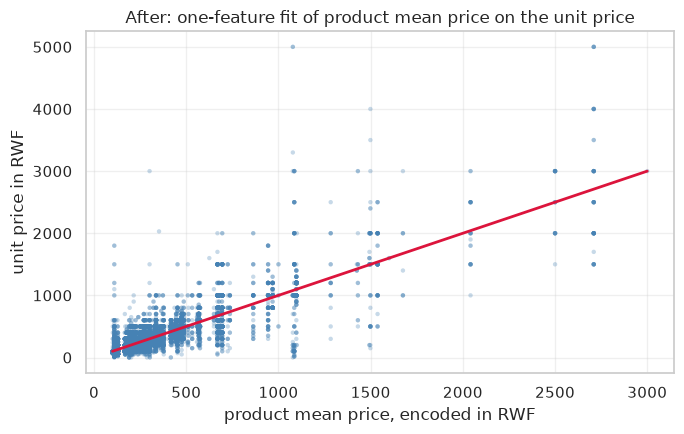

slope: 1.000 | intercept: 0.0


In [18]:
plot_frame = pd.DataFrame({"product_mean_price": plot_x, TARGET: plot_y})
one_feature_model = LinearRegression().fit(plot_frame[["product_mean_price"]], plot_frame[TARGET])

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_scatter(ax, plot_x, plot_y, line=one_feature_model)
ax.set_xlabel("product mean price, encoded in RWF")
ax.set_ylabel("unit price in RWF")
ax.set_title("After: one-feature fit of product mean price on the unit price")
plt.tight_layout()
plt.show()

print(f"slope: {one_feature_model.coef_[0]:.3f} | intercept: {one_feature_model.intercept_:.1f}")

The red line has slope 1.000 and intercept 0.0, and that is what it must be: the feature is the product
mean of the target itself, so regressing the target on it returns the diagonal through those means. The
line is not evidence of a good model; the width of each strip around it is the part a single number
cannot explain.

That leftover spread is what the district, the setting, the unit and the month have to account for, and
it is why the five-input pipelines in Section E beat any one-feature fit. This line was fitted for the
picture only and is not saved.

## Section G: Save and predict

The winning pipeline is saved with the metadata and the training frame the API needs, so the service
never redefines the column list, the allowed categories or the price bounds.

In [19]:
train_frame = X_train[FEATURE_COLUMNS].copy()
train_frame[TARGET] = y_train.to_numpy()
train_frame = train_frame.reset_index(drop=True)

allowed_values = {
    column: sorted(X_train[column].astype(str).unique().tolist())
    for column in CATEGORICAL_FEATURES
}
input_types = {
    column: ("categorical" if column in CATEGORICAL_FEATURES else "integer")
    for column in FEATURE_COLUMNS
}

low_price = float(y_train.quantile(0.001))
high_price = float(y_train.quantile(0.999))
price_range = {
    "p001": low_price,
    "p999": high_price,
    "margin": PRICE_MARGIN,
    "min": round(low_price * (1 - PRICE_MARGIN), 2),
    "max": round(high_price * (1 + PRICE_MARGIN), 2),
}

product_unit_medians = (
    train_frame.groupby(["s8cq0", "s8cq14"])[TARGET].median().unstack("s8cq14").round(2)
)
median_price_by_product_unit = {
    product: {unit: float(value) for unit, value in row.dropna().items()}
    for product, row in product_unit_medians.iterrows()
}
median_price_by_district = {
    district: float(value)
    for district, value in train_frame.groupby("district")[TARGET].median().round(2).items()
}

metadata = {
    "target": TARGET,
    "target_unit": "RWF",
    "input_columns": FEATURE_COLUMNS,
    "input_types": input_types,
    "numeric_columns": NUMERIC_FEATURES,
    "categorical_columns": CATEGORICAL_FEATURES,
    "allowed_values": allowed_values,
    "month_range": {"min": 1, "max": 12, "median": int(train_frame["s0q18m"].median())},
    "price_range": price_range,
    "median_price_by_product_unit": median_price_by_product_unit,
    "median_price_by_district": median_price_by_district,
    "target_cap": CAP,
    "model_name": best_name,
    "metrics": {
        name: {
            "train_mse": float(scores.loc[name, "train_mse"]),
            "test_mse": float(scores.loc[name, "test_mse"]),
            "test_rmse": float(scores.loc[name, "test_rmse"]),
        }
        for name in scores.index
    },
    "sklearn_version": sklearn.__version__,
}

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(
    {"pipeline": best_pipeline, "metadata": metadata, "train_frame": train_frame},
    MODEL_PATH,
    compress=3,
)

print(MODEL_PATH)
print(f"model: {best_name} | test MSE: {scores.loc[best_name, 'test_mse']:.1f} "
      f"| test RMSE: {scores.loc[best_name, 'test_rmse']:.1f} RWF")
print(f"train_frame: {len(train_frame):,} rows x {train_frame.shape[1]} columns "
      f"{list(train_frame.columns)}")
print(f"input columns: {len(FEATURE_COLUMNS)} | categorical vocabularies: "
      f"{ {k: len(v) for k, v in allowed_values.items()} }")
print(f"scikit-learn: {metadata['sklearn_version']} | file size: {MODEL_PATH.stat().st_size / 1024:.0f} KiB")

/home/elijahladdie/Projects/alu-learning/year-2/Mathematics/summative-assignment/linear_regression_model/summative/API/best_model.pkl
model: LinearRegression | test MSE: 20075.4 | test RMSE: 141.7 RWF
train_frame: 15,838 rows x 6 columns ['s8cq0', 's8cq14', 'district', 'ur', 's0q18m', 's8cq15']
input columns: 5 | categorical vocabularies: {'s8cq0': 97, 's8cq14': 5, 'district': 27, 'ur': 2}
scikit-learn: 1.9.1 | file size: 156 KiB


### G2: the app's form schema

The phone must not keep its own copy of the product list, the units, the districts or the month
range. That is how a client silently drifts from the model. So this cell reads the saved metadata
back out of `best_model.pkl` and writes `FlutterApp/lib/generated/form_schema.dart`, which the app
imports and renders. The field specs, the allowed values and both ranges come from one place: the
bundle the API also loads.

In [20]:
import json
from pathlib import Path

APP_SCHEMA_PATH = Path.cwd().parent / "FlutterApp" / "lib" / "generated" / "form_schema.dart"
FIELD_KEYS = {
    "s8cq0": ("product", "Product", "product"),
    "s8cq14": ("unit", "Unit", "unit"),
    "district": ("district", "District", "district"),
    "ur": ("ur", "Setting", "setting"),
    "s0q18m": ("month", "Month", "month"),
}
VALUE_LISTS = {
    "product": "productValues",
    "unit": "unitValues",
    "district": "districtValues",
    "ur": "settingValues",
}


def dart_string(value) -> str:
    """A single-quoted Dart literal, with the three characters that need escaping."""
    text = str(value).replace("\\", "\\\\").replace("'", "\\'").replace("$", "\\$")
    return f"'{text}'"


def dart_double(value) -> str:
    """A Dart double literal that always keeps a decimal point."""
    text = f"{float(value):.2f}".rstrip("0")
    return text + "0" if text.endswith(".") else text


def dart_values(name: str, values: list[str]) -> str:
    entries = "".join(f"  {dart_string(value)},\n" for value in values)
    return f"const List<String> {name} = <String>[\n{entries}];\n"


def dart_spec(key: str, label: str, kind: str, values: str, extra: str = "") -> str:
    lines = ["  FieldSpec(", f"    key: '{key}',", f"    label: '{label}',",
             f"    kind: FieldKind.{kind},", f"    values: {values},"]
    if extra:
        lines.append(extra)
    lines.append("  ),")
    return "\n".join(lines)


saved = joblib.load(MODEL_PATH)["metadata"]
allowed = saved["allowed_values"]
price_range = saved["price_range"]
month_range = saved["month_range"]

specs = []
for column in saved["input_columns"]:
    key, label, kind = FIELD_KEYS[column]
    if key == "month":
        specs.append(dart_spec(
            "month", "Month", "month", "<String>[]",
            extra="    minValue: monthMin,\n    maxValue: monthMax,",
        ))
    else:
        specs.append(dart_spec(key, label, kind, VALUE_LISTS[key]))

template = """// GENERATED FILE - DO NOT EDIT BY HAND.
// Written by linear_regression/multivariate.ipynb (cell G2) from best_model.pkl.
// The API and this app read the same metadata, so neither defines a list or a range alone.

/// How the phone collects one model input.
enum FieldKind { product, unit, district, setting, month }

/// One input of POST /predict, in the order the API expects.
class FieldSpec {
  const FieldSpec({
    required this.key,
    required this.label,
    required this.kind,
    required this.values,
    this.minValue,
    this.maxValue,
  });

  /// JSON key sent to the API.
  final String key;

  /// Label shown above the input.
  final String label;

  final FieldKind kind;

  /// Every value the model was trained on, empty for the numeric month.
  final List<String> values;

  /// Inclusive bounds, set only for the month.
  final int? minValue;
  final int? maxValue;
}

const String modelName = __MODEL_NAME__;
const String targetPriceUnit = __TARGET_UNIT__;
const int monthMin = __MONTH_MIN__;
const int monthMax = __MONTH_MAX__;
const double priceMin = __PRICE_MIN__;
const double priceMax = __PRICE_MAX__;

__PRODUCTS__
__UNITS__
__DISTRICTS__
__SETTINGS__
const List<FieldSpec> fieldSpecs = <FieldSpec>[
__SPECS__];

/// The spec for one API field; throws rather than inventing a fallback.
FieldSpec specFor(String key) {
  for (final FieldSpec spec in fieldSpecs) {
    if (spec.key == key) {
      return spec;
    }
  }
  throw ArgumentError.value(key, 'key', 'not a field in form_schema.dart');
}
"""

dart = (
    template.replace("__MODEL_NAME__", dart_string(saved["model_name"]))
    .replace("__TARGET_UNIT__", dart_string(saved.get("target_unit", "RWF")))
    .replace("__MONTH_MIN__", str(int(month_range["min"])))
    .replace("__MONTH_MAX__", str(int(month_range["max"])))
    .replace("__PRICE_MIN__", dart_double(price_range["min"]))
    .replace("__PRICE_MAX__", dart_double(price_range["max"]))
    .replace("__PRODUCTS__", dart_values("productValues", allowed["s8cq0"]))
    .replace("__UNITS__", dart_values("unitValues", allowed["s8cq14"]))
    .replace("__DISTRICTS__", dart_values("districtValues", allowed["district"]))
    .replace("__SETTINGS__", dart_values("settingValues", allowed["ur"]))
    .replace("__SPECS__", "\n".join(specs) + "\n")
)

APP_SCHEMA_PATH.parent.mkdir(parents=True, exist_ok=True)
APP_SCHEMA_PATH.write_text(dart, encoding="utf-8")

print(APP_SCHEMA_PATH)
print(f"fields: {[spec.split(chr(39))[1] for spec in specs]}")
print(f"values: products={len(allowed['s8cq0'])}, units={len(allowed['s8cq14'])}, "
      f"districts={len(allowed['district'])}, settings={len(allowed['ur'])}")
print(f"month range: {month_range['min']}-{month_range['max']} | "
      f"price range: {price_range['min']:.2f}-{price_range['max']:.2f} RWF")
print(f"lines: {len(dart.splitlines())}")

/home/elijahladdie/Projects/alu-learning/year-2/Mathematics/summative-assignment/linear_regression_model/summative/FlutterApp/lib/generated/form_schema.dart
fields: ['product', 'unit', 'district', 'ur', 'month']
values: products=97, units=5, districts=27, settings=2
month range: 1-12 | price range: 13.48-1575.00 RWF
lines: 228


In [21]:
bundle = joblib.load(MODEL_PATH)
print(f"bundle keys: {sorted(bundle)}")
print(f"train_frame columns: {list(bundle['train_frame'].columns)}")

sample = X_test.iloc[0].to_dict()
predicted = predict_one(MODEL_PATH, sample)
actual = float(y_test.iloc[0])

print(f"\nsample: {sample}")
print(f"predicted: {predicted:.2f} RWF | actual: {actual:.2f} RWF | difference: {predicted - actual:+.2f}")

bundle keys: ['metadata', 'pipeline', 'train_frame']
train_frame columns: ['s8cq0', 's8cq14', 'district', 'ur', 's0q18m', 's8cq15']

sample: {'s8cq0': 'Banana - cooking _Inyamunyo_', 's8cq14': 'unknown', 'district': 'Nyarugenge', 'ur': 'Rural', 's0q18m': 4}
predicted: 273.69 RWF | actual: 250.00 RWF | difference: +23.69


`predict_one` reloads the bundle and predicts one complete input row; on the first test row it returns
273.69 RWF against an actual 250.00 RWF. The bundle carries three objects: `pipeline` (the fitted
winner), `metadata` and `train_frame`.

`metadata` holds the input columns and their types, the allowed values per categorical column, the month
range 1 to 12 with a median month of 7, the price range (0.1th percentile 14.18 and 99.9th percentile
1,500.00, with a 5% margin, giving 13.48 to 1,575.00), the median price per product and unit, the median
price per district, the model name, the metrics and the scikit-learn version (1.9.1). The price
percentiles are computed on the training target, so the upper end is the 1,500 RWF cap.

`train_frame` holds the cleaned training rows with only the five inputs and the target, 15,838 rows by 6
columns, so `/retrain` can refit from the pickle alone without a separate CSV.

## Section H: District affordability

`district_affordability(pipeline, metadata)` prices one fixed basket in every district, in both the
rural and the urban setting, at the median interview month. The basket is the five most frequently
priced food products in the extract, each in its usual unit. Only the district and the setting change,
so the ordering is a like-for-like comparison of what the same shopping list costs.

In [22]:
affordability = district_affordability(best_pipeline, metadata)
basket = price_basket()
print("basket:", basket.to_dict("records"))
print(f"districts: {len(affordability)} | month used: {metadata['month_range']['median']}")
affordability

basket: [{'s8cq0': 'Dry beans', 's8cq14': 'Kg'}, {'s8cq0': 'Amarante _small leafed green_', 's8cq14': 'Kg'}, {'s8cq0': 'Fresh bean', 's8cq14': 'Kg'}, {'s8cq0': 'Cassava leaves', 's8cq14': 'Kg'}, {'s8cq0': 'Maize _fresh_', 's8cq14': 'Kg'}]
districts: 27 | month used: 7


,rural_basket_rwf,urban_basket_rwf,mean_basket_rwf
district,,,
Nyarugenge,1712,1705,1708
Rulindo,1575,1567,1571
Nyabihu,1566,1558,1562
Gasabo,1564,1557,1561
Kirehe,1547,1540,1544
Kicukiro,1536,1528,1532
Gakenke,1530,1522,1526
Musanze,1505,1497,1501
Gicumbi,1485,1477,1481


The table runs from the most to the least expensive district. Nyarugenge leads at 1,708 RWF for the
basket, on average across the two settings, and Rubavu is cheapest at 1,231 RWF, so the same shopping list
is priced about 39% higher at the top than at the bottom. The rural column runs a few RWF above the urban
one in every district, a gap far smaller than the gap between districts.

**Caveat.** These are model estimates learned from the 2016 to 2017 EICV5 survey, not live prices. They
show the pattern the survey recorded, seasonal and local gaps included, so read them as a starting point
for a budget conversation rather than as a price list for today.

## Summary

* The extract is 166,044 rows by 38 columns; 19,947 rows (12%) report a unit price and support modelling.
* The target is the unit price in RWF. `s8cq14` is kept as a category: `Kg`, `Lit`, `Igice` and `Ipaki`
  are recorded, and 65.38% of the priced rows have no unit and form their own `unknown` category.
* Visit fields, repeat-visit shares, survey-design fields and identifiers are dropped; `key_17` survives
  only as the household group id that groups the split.
* `s8cq2` falls to the 60% missing rule, and `s8cq15` stays the target for the same reason it cannot be
  an input.
* Sixteen candidate columns evidence the eight-feature rule; the model keeps five inputs: product, unit,
  district, setting and month.
* The split is grouped on `key_17` at 80/20, and the target is capped at the training 99th percentile
  (1,500 RWF).
* `LinearRegression` wins with a test MSE of 20,075.4 and a test RMSE of 141.7 RWF. The log1p wrapper
  scores 21,419.9 and is not kept, and the capped tree and forest underfit.
* The bundle is saved to `summative/API/best_model.pkl` with the pipeline, the metadata and the training
  frame.
* Section H prices one basket of five common products per district and orders the districts from most to
  least expensive.